<a href="https://colab.research.google.com/github/beattytyler/FashionMNIST-Classification/blob/main/Lab_6_Image_Classifcation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
'''
Authors: Tyler Beatty, Justin Hoang
Date: October 2026
'''

'\nAuthors: Tyler Beatty, Justin Hoang\nDate: October 2026\n'

In [ ]:
import numpy as np
from torchvision import datasets, transforms
from sklearn.model_selection import train_test_split
from skimage.transform import resize
from skimage.feature import hog

In [ ]:
# Fashion-MNIST dataset
transform = transforms.Compose([
    transforms.ToTensor(), # (1, 28, 28); scales values from [0, 255] to [0, 1]
])

# training dataset
trainset = datasets.FashionMNIST(
    root='./data',
    train=True,
    download=True,
    transform=transform
)
# testing dataset
testset = datasets.FashionMNIST(
    root='./data',
    train=False,
    download=True,
    transform=transform)

100%|██████████| 26.4M/26.4M [00:01<00:00, 17.5MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 319kB/s]
100%|██████████| 4.42M/4.42M [00:00<00:00, 5.00MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 19.9MB/s]


In [ ]:
x = np.zeros((1250, 28, 28), dtype='float')
y = np.zeros((1250), dtype='uint8')

# split data into 10 classes, 125 samples each (pre filtering)

top_count = 0 # t-shirt/top
trouser_count = 0
pullover_count = 0
dress_count = 0
coat_count = 0
sandal_count = 0
shirt_count = 0
sneaker_count = 0
bag_count = 0
ankle_boot_count = 0


counter = 0

for i in range(len(trainset)):
  image, label = trainset[i]

  if label == 0 and top_count < 125:
    x[counter] = image.squeeze().numpy()
    y[counter] = label
    counter += 1
    top_count += 1

  if label == 1 and trouser_count < 125:
    x[counter] = image.squeeze().numpy()
    y[counter] = label
    counter += 1
    trouser_count += 1

  if label == 2 and pullover_count < 125:
    x[counter] = image.squeeze().numpy()
    y[counter] = label
    counter += 1
    pullover_count += 1

  if label == 3 and dress_count < 125:
    x[counter] = image.squeeze().numpy()
    y[counter] = label
    counter += 1
    dress_count += 1

  if label == 4 and coat_count < 125:
    x[counter] = image.squeeze().numpy()
    y[counter] = label
    counter += 1
    coat_count += 1

  if label == 5 and sandal_count < 125:
    x[counter] = image.squeeze().numpy()
    y[counter] = label
    counter += 1
    sandal_count += 1

  if label == 6 and shirt_count < 125:
    x[counter] = image.squeeze().numpy()
    y[counter] = label
    counter += 1
    shirt_count += 1

  if label == 7 and sneaker_count < 125:
    x[counter] = image.squeeze().numpy()
    y[counter] = label
    counter += 1
    sneaker_count += 1

  if label == 8 and bag_count < 125:
    x[counter] = image.squeeze().numpy()
    y[counter] = label
    counter += 1
    bag_count += 1

  if label == 9 and ankle_boot_count < 125:
    x[counter] = image.squeeze().numpy()
    y[counter] = label
    counter += 1
    ankle_boot_count += 1

  if counter == 1250:
    break


In [ ]:
# 80/20 split
x_train, x_test, y_train, y_test = train_test_split(
    x, y,
    test_size=250,
    train_size=1000,
    stratify=y, # to keep same proportional distribution
    random_state=0 # keep for reproduceable results
    )

In [ ]:
# Resize to fixed size
def preProcess(image):
  return resize(image, (32, 32))

resized_x_train = [preProcess(x) for x in x_train]
resized_x_test = [preProcess(x) for x in x_test]

In [ ]:
# Calculate all HOG features
training_hogs = [
    hog(
      img,
      orientations=8,
      pixels_per_cell=(8,8),
      cells_per_block=(2,2),
      block_norm='L2'
  ) for img in resized_x_train
]

test_hogs = [
    hog(
      img,
      orientations=8,
      pixels_per_cell=(8,8),
      cells_per_block=(2,2),
      block_norm='L2'
  ) for img in resized_x_test
]

In [ ]:
# Test hog features
print(len(training_hogs))
print(len(test_hogs))

print(training_hogs[0].shape)

1000
250
(288,)


In [ ]:
# K_NN Classifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt
import numpy as np

# Convert HOG features into NumPy arrays
X_train = np.array(training_hogs)
X_test = np.array(test_hogs)

# K values to test
k_values = [1, 3, 5, 7, 9, 11]
accuracies = []

# Test each K value
for k in k_values:

    # Create K-NN classifier
    knn = KNeighborsClassifier(n_neighbors=k)

    # Train using HOG features
    knn.fit(X_train, y_train)

    # Predict test labels
    y_pred = knn.predict(X_test)

    # Calculate accuracy
    accuracy = accuracy_score(y_test, y_pred)
    accuracies.append(accuracy)

    print(f"K = {k}, Accuracy = {accuracy:.4f}")

# Find the best K
best_index = np.argmax(accuracies)
best_k = k_values[best_index]

print(f"\nBest K: {best_k}")
print(f"Best Accuracy: {accuracies[best_index]:.4f}")


K = 1, Accuracy = 0.7360
K = 3, Accuracy = 0.7600
K = 5, Accuracy = 0.7680
K = 7, Accuracy = 0.7600
K = 9, Accuracy = 0.7480
K = 11, Accuracy = 0.7480

Best K: 5
Best Accuracy: 0.7680


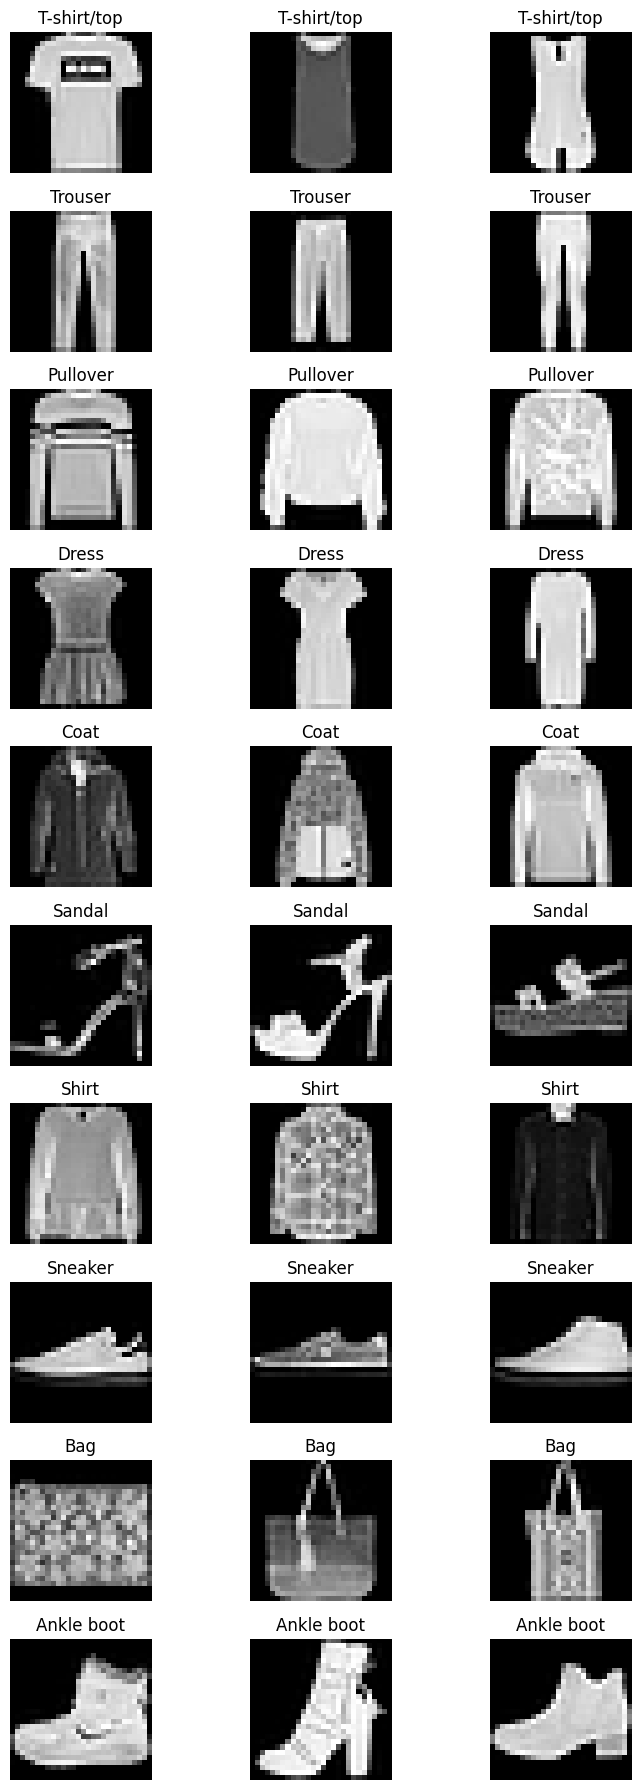

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

class_names = [
    "T-shirt/top", "Trouser", "Pullover", "Dress",
    "Coat", "Sandal", "Shirt", "Sneaker",
    "Bag", "Ankle boot"
]

# Create a grid of 30 images
fig, axes = plt.subplots(10, 3, figsize=(8, 18))

for label in range(10):
    indices = np.where(y == label)[0][:3]

    for col, idx in enumerate(indices):
        axes[label, col].imshow(x[idx], cmap="gray")
        axes[label, col].set_title(class_names[label])
        axes[label, col].axis("off")

plt.tight_layout()
plt.savefig("sample_images.png", dpi=300, bbox_inches="tight")
plt.show()


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd
import numpy as np

# Create table for K values and accuracy
results = pd.DataFrame({
    "K Value": k_values,
    "Accuracy (%)": np.array(accuracies) * 100
})

# Round accuracy to 2 decimal places
results["Accuracy (%)"] = results["Accuracy (%)"].round(2)

# Display table
display(results)

# Print best K and final accuracy
print(f"Best K: {best_k}")
print(f"Final Accuracy: {final_accuracy * 100:.2f}%")


,K Value,Accuracy (%)
0,1,73.6
1,3,76.0
2,5,76.8
3,7,76.0
4,9,74.8
5,11,74.8


Best K: 5
Final Accuracy: 76.80%


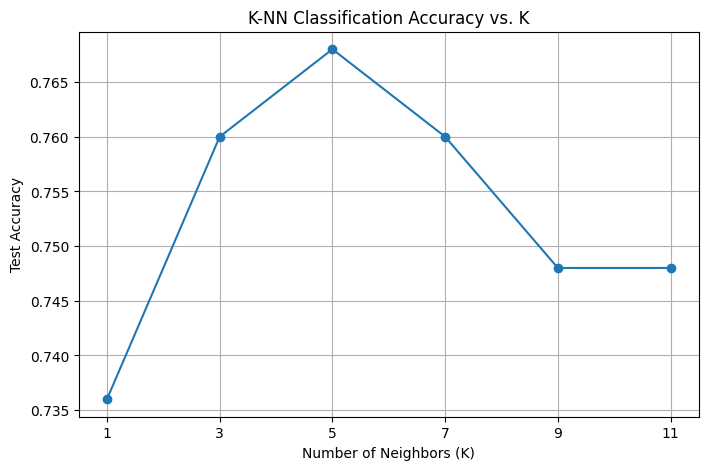

In [ ]:
# Plot Accuracy vs. K
plt.figure(figsize=(8, 5))

plt.plot(k_values, accuracies, marker='o')

plt.xlabel("Number of Neighbors (K)")
plt.ylabel("Test Accuracy")
plt.title("K-NN Classification Accuracy vs. K")

plt.xticks(k_values)
plt.grid(True)

plt.show()


In [ ]:
# Create final model using best K
final_knn = KNeighborsClassifier(n_neighbors=best_k)

# Train using HOG training features
final_knn.fit(X_train, y_train)

# Predict test labels
final_predictions = final_knn.predict(X_test)

# Calculate final accuracy
final_accuracy = accuracy_score(y_test, final_predictions)

print(f"Final K: {best_k}")
print(f"Final Test Accuracy: {final_accuracy:.4f}")


Final K: 5
Final Test Accuracy: 0.7680


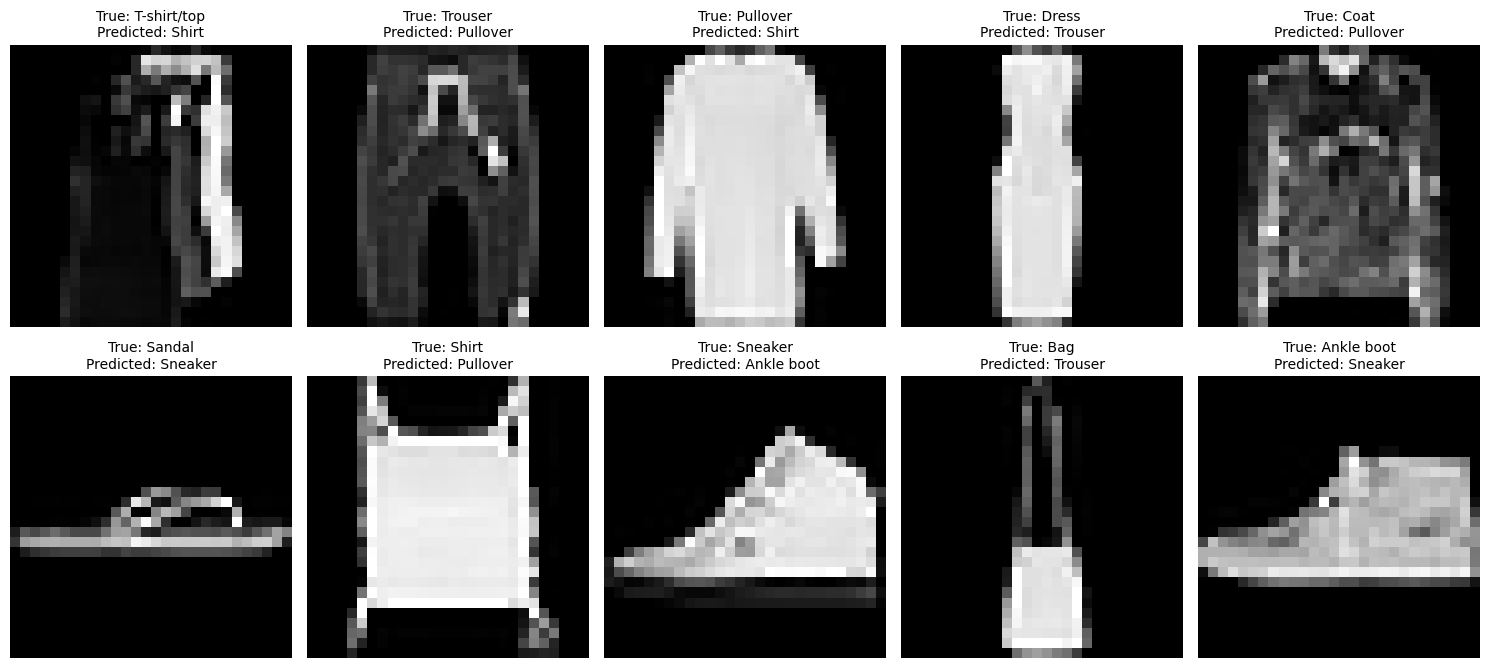

Displayed 10 of 10 classes.


In [ ]:

# Find incorrect predictions
misclassified = np.where(final_predictions != y_test)[0]

# Store one misclassified image per class
examples = []

for label in range(10):
    matches = [
        i for i in misclassified
        if y_test[i] == label
    ]

    if matches:
        examples.append(matches[0])

# Create figure
fig, axes = plt.subplots(2, 5, figsize=(15, 7))
axes = axes.flatten()

for ax in axes:
    ax.axis("off")

for j, i in enumerate(examples):
    axes[j].imshow(x_test[i], cmap="gray")

    true_label = class_names[int(y_test[i])]
    predicted_label = class_names[int(final_predictions[i])]

    axes[j].set_title(
        f"True: {true_label}\nPredicted: {predicted_label}",
        fontsize=10
    )

    axes[j].axis("off")

plt.tight_layout()
plt.savefig("misclassifications.png", dpi=300, bbox_inches="tight")
plt.show()

print(f"Displayed {len(examples)} of 10 classes.")

for label in range(10):
    if not any(y_test[i] == label for i in examples):
        print(f"No misclassification found for {class_names[label]}")
